# Training experiments

Launcher for the MGMT training pipeline: it picks a backbone and a validation fold, runs each experiment below through `python -m training.run train`, and reads the run folders back. Training logic lives in `training/`, so everything here is settings and reading results.

Each experiment is a list of `--set key=value` overrides on `configs/train.yaml` and `configs/backbones/<backbone>.yaml`. A `smoke` run trains on the validation patients to show the pipeline runs end to end; its record is marked invalid for results. A real run needs `macenko_reference_patch_ids` set for the fold. Values for Experiment A (tiles per patient) and Experiment B (JPEG quality) are not decided yet, so they are not listed. Add them as rows when they are.

In [1]:
import os
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "training").is_dir() else Path.cwd().parent
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import torch
from training import report

In [2]:
BACKBONE = "swin_v2_t"            # swin_v2_t or convnext_v2_t
FOLD = 0                          # validation fold, 0 to 4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Experiment A rows: set max_tiles_per_patient=N (training pool) and max_eval_tiles_per_patient=N.
# The cap at packaging is per slide (5,508), so a patient with several slides has more tiles: half B
# has 52 of 116 patients above 5,508 and a largest patient of 38,556. N must be at most the largest
# patient count in the package, or the run stops. For "all tiles" use null, not a larger number.
EXPERIMENTS = {
    "smoke": ["smoke_train_on_validation=true", "tiles_per_bag=8",
              "validation_tiles_per_patient=64", "max_eval_tiles_per_patient=64",
              "stages_real=[{learning_rate: 1.0e-5, epochs: 2, class_weighted: true}]"],
    "baseline": [],
}
SELECTED = ["smoke"]

In [3]:
runs = {name: report.launch(BACKBONE, FOLD, EXPERIMENTS[name], DEVICE) for name in SELECTED}
runs

{'smoke': PosixPath('/Users/dcarrillo/ws/chatu/school-ms-ai/fall-26/deep-learning-643/project/gbm-mgmt-wsi/data/runs/swin_v2_t_fold0_20261117T213752Z')}

In [4]:
report.summarize(runs)

,run,valid_for_results,best_validation_loss,best_epoch,epochs_run,validation_patients,auroc
0,smoke,False,0.780518,1.0,2,19,0.727273


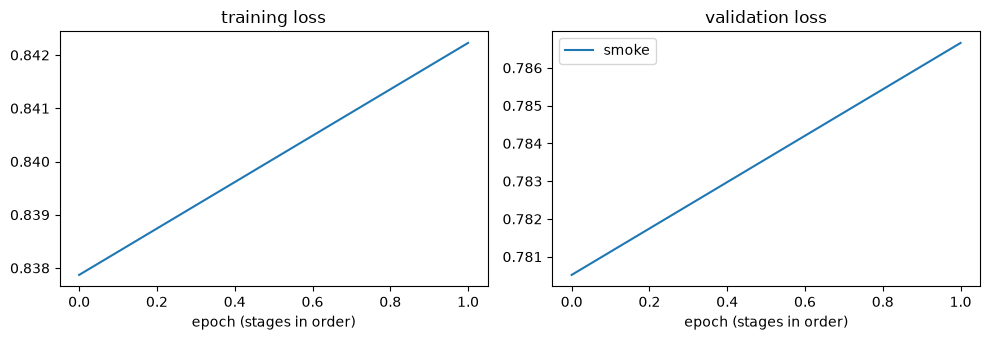

In [5]:
figure = report.plot_curves(runs)
figure.savefig(REPO / "data" / "runs" / f"curves_{BACKBONE}_fold{FOLD}.png", dpi=150)